# Figure 1 — cfDNA molecular features and correlation to gene expression

- a: normalized coverage at TSSs of housekeeping (HK) vs lowly expressed (PAU) genes over the panel of normals (mean ± SD);
- b: distribution of mean coverage per 10 kb TSS window for the two gene sets (Mann-Whitney U test);
- c: mean per-sample Pearson correlation of each fragmentomic feature with reference gene-group expression (Esfahani et al.), all TSSs vs QC-filtered TSSs.

Source data, written by `export/export_fig1.py`:
- `data/fig1a_coverage_profiles.csv` — per-position mean/SD of the normalized coverage profile per gene set;
- `data/fig1b_locus_coverage.csv` — per-sample per-locus mean coverage for the two gene sets;
- `data/fig1c_expression_correlations.csv` — per-sample Pearson r per feature, all TSSs and QC TSSs.

The panel of normals is the 50 participants with role `panel_of_normals` in `accessory_files/cris_manifest.csv`; it excludes the deep-sequenced healthy donors, so the figure is the same for both cohort variants. Panel a uses only panel samples with a per-locus coverage array (`n_samples` in `fig1a_coverage_profiles.csv`). Run top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from scipy.stats import gaussian_kde, mannwhitneyu

import _figstyle as fs
fs.apply()
plt.rcParams["hatch.linewidth"] = 0.4

HK_COLOR = (148 / 255, 203 / 255, 236 / 255)
PAU_COLOR = (194 / 255, 106 / 255, 119 / 255)
FEATURE_NAMES = {"fslr": "FSLR", "fslr_coverage": "FSLRC", "griffin_diff": "GD",
                 "rcov": "RCOV", "mwh": "MWH"}
FEATURES = list(FEATURE_NAMES)
FEATURE_COLORS = {f: fs.FEATURE[n] for f, n in FEATURE_NAMES.items()}

prof = pd.read_csv("data/fig1a_coverage_profiles.csv")
locus = pd.read_csv("data/fig1b_locus_coverage.csv")
corr = pd.read_csv("data/fig1c_expression_correlations.csv")
N_SAMPLES = corr["sample_index"].nunique()                     # panels b, c
N_PROFILE = int(prof["n_samples"].iloc[0]) if "n_samples" in prof else N_SAMPLES   # panel a
print(f"PoN samples: {N_SAMPLES} (panels b, c), {N_PROFILE} with coverage arrays (panel a); "
      f"per-locus rows: {len(locus)}")

PoN samples: 50 (panels b, c), 50 with coverage arrays (panel a); per-locus rows: 96354


## Panel a — coverage profiles at the TSS

In [2]:
def panel_a(ax):
    for gs, label, color in [("HK", "HK genes", HK_COLOR),
                             ("PAU", "PAU genes", PAU_COLOR)]:
        d = prof[prof["gene_set"] == gs].sort_values("position")
        mean = d["mean_normalized_coverage"].to_numpy()
        sd = d["sd_normalized_coverage"].to_numpy()
        ax.plot(d["position"], mean, color=color, linewidth=1.0, label=label)
        ax.fill_between(d["position"], mean - sd, mean + sd, color=color, alpha=0.25, linewidth=0)
    ax.axvline(x=0, color=fs.CHANCE, linestyle=":", linewidth=0.7)
    ax.set_xlabel("Distance from TSS (kb)")
    ax.set_ylabel("Normalized coverage")
    ax.legend(loc="lower right", title=f"Mean \u00b1 SD (n = {N_PROFILE})")
    ax.set_xlim(-5000, 5000)
    ax.set_xticks([-5000, -2500, 0, 2500, 5000])
    ax.set_xticklabels(["\u22125", "\u22122.5", "TSS", "2.5", "5"])
    fs.value_grid(ax)

## Panel b — per-locus mean coverage distributions

In [3]:
def panel_b(ax):
    hk = locus.loc[locus["gene_set"] == "HK", "mean_coverage"].to_numpy()
    pau = locus.loc[locus["gene_set"] == "PAU", "mean_coverage"].to_numpy()
    n_hk_tss = locus[locus["gene_set"] == "HK"].groupby("sample_id").size().max()
    n_pau_tss = locus[locus["gene_set"] == "PAU"].groupby("sample_id").size().max()

    y_max, means = 0, {}
    x_max = 5
    for label, data, color, n_tss in [("HK genes", hk, HK_COLOR, n_hk_tss),
                                      ("PAU genes", pau, PAU_COLOR, n_pau_tss)]:
        kde = gaussian_kde(data, bw_method="scott")
        x_range = np.linspace(max(data.min(), 0), x_max, 500)
        density = kde(x_range)
        y_max = max(y_max, density.max())
        ax.plot(x_range, density, color=color, linewidth=1.0,
                label=f"{label} ({n_tss:,} TSSs)")
        ax.fill_between(x_range, density, alpha=0.15, color=color, linewidth=0)
        for q_val, q_label in zip(np.percentile(data, [25, 50, 75]), ["Q1", "Median", "Q3"]):
            ax.vlines(q_val, 0, kde(q_val)[0], colors=color, linestyles="dashed",
                      linewidth=0.8 if q_label == "Median" else 0.5)
        means[label] = np.mean(data)

    stat, pval = mannwhitneyu(hk, pau, alternative="two-sided")
    p_text = "p < 0.001" if pval < 0.001 else f"p = {pval:.3f}"
    left, right = sorted([means["HK genes"], means["PAU genes"]])
    tick_h, bracket_y = y_max * 0.03, y_max * 1.08
    ax.plot([left, left, right, right], [bracket_y - tick_h, bracket_y, bracket_y, bracket_y - tick_h],
            color="black", linewidth=0.6, clip_on=False)
    ax.text((left + right) / 2, bracket_y + y_max * 0.015, p_text, ha="center",
            va="bottom", fontsize=fs.VALUE, fontstyle="italic")

    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.84), handlelength=1.2)
    ax.set_xlabel("Mean coverage per 10 kb TSS window")
    ax.set_ylabel("Density")
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, bracket_y * 1.15)
    fs.value_grid(ax)
    return stat, pval

## Panel c — feature–expression correlations

In [4]:
def panel_c(ax):
    all_means, all_stds, qc_means, qc_stds, colors, labels = [], [], [], [], [], []
    for feat in FEATURES:
        for sink_m, sink_s, tss_set in [(all_means, all_stds, "all"),
                                        (qc_means, qc_stds, "qc")]:
            v = corr[(corr["feature"] == feat)
                     & (corr["tss_set"] == tss_set)]["pearson_r"].dropna()
            sink_m.append(v.mean())
            sink_s.append(v.std(ddof=0))
        colors.append(FEATURE_COLORS[feat])
        labels.append(FEATURE_NAMES[feat])

    bar_height = 0.38
    positions = np.arange(len(FEATURES)) * 1.0
    err = {"linewidth": 0.6, "ecolor": "black", "capsize": 1.5, "capthick": 0.6}
    ax.barh(positions - bar_height / 2, all_means, bar_height, xerr=all_stds,
            color=colors, error_kw=err, edgecolor="black", linewidth=0.4, zorder=2)
    ax.barh(positions + bar_height / 2, qc_means, bar_height, xerr=qc_stds,
            color=colors, alpha=0.7, error_kw=err, edgecolor="black", linewidth=0.4,
            hatch="//////", zorder=2)

    # value labels just past the end of each error bar, outside the bars
    for means, stds, offset in [(all_means, all_stds, -bar_height / 2),
                                (qc_means, qc_stds, +bar_height / 2)]:
        for mean, std, pos in zip(means, stds, positions):
            x_pos = mean + std + 0.025 if mean > 0 else mean - std - 0.025
            ha = "left" if mean > 0 else "right"
            ax.text(x_pos, pos + offset, f"{mean:.3f}".replace("-", "\u2212"), ha=ha, va="center",
                    fontsize=fs.VALUE, color=fs.NEUTRAL)

    from matplotlib.patches import Patch
    handles = [Patch(facecolor="#bdbdbd", edgecolor="black", linewidth=0.4, label="All TSSs"),
               Patch(facecolor="#bdbdbd", edgecolor="black", linewidth=0.4, alpha=0.7, hatch="//////",
                     label="QC-filtered TSSs")]
    ax.legend(handles=handles, loc="lower right", title=f"Mean \u00b1 SD (n = {N_SAMPLES})")
    ax.set_xlabel("Pearson correlation with expression (r)")
    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    ax.tick_params(axis="y", length=0)
    ax.axvline(x=0, color="black", linewidth=0.6, zorder=3)
    ax.set_xlim(-0.8, 1.0)
    ax.set_xticks([-0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8])
    fs.value_grid(ax, axis="x")
    ax.invert_yaxis()

## Assemble Figure 1

saved output/fig1.png/.pdf at 178 x 60 mm


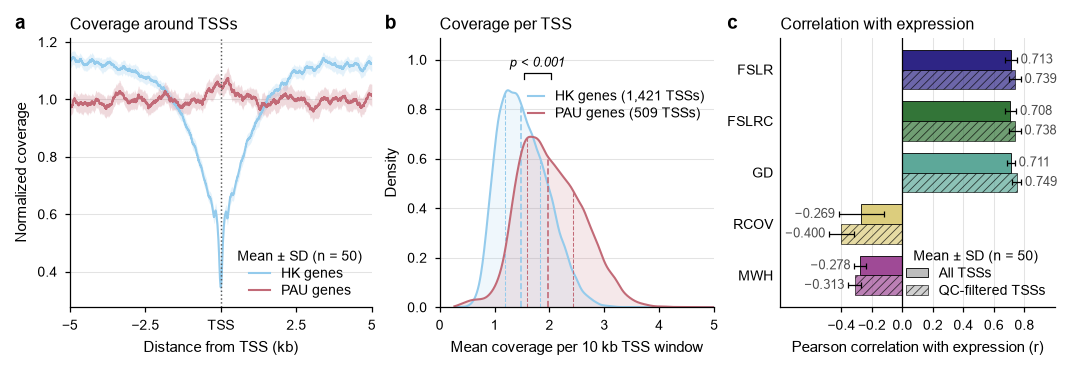

In [5]:
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=fs.size(rows=1), layout="constrained",
                                       gridspec_kw={"width_ratios": [1.1, 1, 1]})
panel_a(ax_a)
stat, pval = panel_b(ax_b)
panel_c(ax_c)
fs.panel(ax_a, "a", "Coverage around TSSs")
fs.panel(ax_b, "b", "Coverage per TSS")
fs.panel(ax_c, "c", "Correlation with expression")
os.makedirs("output", exist_ok=True)
fs.save(fig, "output/fig1")
plt.show()

## Checks

Asserts p < 0.001 for panel b; for panel c, FSLR, FSLRC and GD correlate above 0.5 (QC set higher than all TSSs) and RCOV, MWH negatively.

In [6]:
print(f"Panel b MWU: U={stat:.0f}, p={pval:.3g}  (manuscript: p < 0.001)")
assert pval < 0.001

print("\nPanel c (mean ± SD over samples):")
for feat in FEATURES:
    vals = {}
    for tss_set in ["all", "qc"]:
        v = corr[(corr["feature"] == feat) & (corr["tss_set"] == tss_set)]["pearson_r"].dropna()
        vals[tss_set] = (v.mean(), v.std(ddof=0))
    print(f"  {FEATURE_NAMES[feat]:<6} all {vals['all'][0]:+.3f} ± {vals['all'][1]:.3f}   "
          f"qc {vals['qc'][0]:+.3f} ± {vals['qc'][1]:.3f}")
    if feat in ("fslr", "fslr_coverage", "griffin_diff"):
        assert vals["qc"][0] > vals["all"][0] > 0.5, f"{feat}: unexpected correlation pattern"
    else:
        assert vals["all"][0] < 0, f"{feat}: expected negative correlation"

Panel b MWU: U=447058634, p=0  (manuscript: p < 0.001)

Panel c (mean ± SD over samples):
  FSLR   all +0.713 ± 0.038   qc +0.739 ± 0.038
  FSLRC  all +0.708 ± 0.038   qc +0.738 ± 0.037
  GD     all +0.711 ± 0.027   qc +0.749 ± 0.030
  RCOV   all -0.269 ± 0.150   qc -0.400 ± 0.082
  MWH    all -0.278 ± 0.038   qc -0.313 ± 0.044
